In [2]:
import os
GPU_ID = "3"  # physical DGX GPU; visible to TensorFlow as /GPU:0
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"

import glob
import random
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model

# -------------------------
# Dataset and model settings
# -------------------------
ROOT_DIR = Path("/raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED")
IMG_HEIGHT = 256
IMG_WIDTH = 384
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)  # (height, width)
BATCH_SIZE = 1
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE_PX = 2
BOUNDARY_TOLERANCE = BOUNDARY_TOLERANCE_PX
PRED_THRESHOLD = 0.5
BASE_FILTERS = [32, 64, 128, 256, 512]  # full-width U-Net++ encoder/decoder schedule
OUTPUT_DIR = "/raid/home/dgx1725/unetpp_mod2_fixedkernel_warwick_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "predicted_masks"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "prediction_visualizations"), exist_ok=True)

# Compatibility aliases: train directories only. Split-aware code below uses SPLIT_DIRS.
IMAGE_DIR = str(ROOT_DIR / "train" / "img")
MASK_DIR = str(ROOT_DIR / "train" / "mask")
SPLIT_DIRS = {
    split: {
        "img": ROOT_DIR / split / "img",
        "mask": ROOT_DIR / split / "mask",
    }
    for split in ("train", "val", "test")
}

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

# GPU check + memory growth. Full paper-width filters are intentionally retained.
physical_gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow version:", tf.__version__)
print("Requested physical GPU ID:", GPU_ID)
print("TensorFlow-visible GPUs:", physical_gpus)
if not physical_gpus:
    raise RuntimeError(
        "TensorFlow sees no GPU. Restart the kernel and launch Jupyter from the DGX "
        "terminal with the appropriate NVIDIA LD_LIBRARY_PATH and CUDA_VISIBLE_DEVICES."
    )
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print("GPU memory-growth setting:", exc)
with tf.device("/GPU:0"):
    _gpu_test = tf.matmul(tf.random.normal((128, 128)), tf.random.normal((128, 128)))
print("GPU matrix test device:", _gpu_test.device)
del _gpu_test

if not ROOT_DIR.is_dir():
    raise FileNotFoundError(f"Dataset root not found: {ROOT_DIR}")
for split, paths in SPLIT_DIRS.items():
    for kind, folder in paths.items():
        if not folder.is_dir():
            raise FileNotFoundError(f"Missing {split}/{kind} directory: {folder}")

print("Dataset root:", ROOT_DIR)
print("Output directory:", OUTPUT_DIR)
for split, paths in SPLIT_DIRS.items():
    print(f"{split:5s} | images={sum(p.is_file() for p in paths['img'].iterdir())} | masks={sum(p.is_file() for p in paths['mask'].iterdir())}")
print("Input tensor shape:", (IMG_HEIGHT, IMG_WIDTH, 3))
print("U-Net++ filter schedule:", BASE_FILTERS)


TensorFlow version: 2.15.1
Requested physical GPU ID: 3
TensorFlow-visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU matrix test device: /job:localhost/replica:0/task:0/device:GPU:0
Dataset root: /raid/home/dgx1725/Warwick_QU_Dataset_Binary_FIXED
Output directory: /raid/home/dgx1725/unetpp_mod2_fixedkernel_warwick_outputs
train | images=133 | masks=133
val   | images=16 | masks=16
test  | images=16 | masks=16
Input tensor shape: (256, 384, 3)
U-Net++ filter schedule: [32, 64, 128, 256, 512]


In [3]:
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".bm", ".tif", ".tiff"}


def canonical_mask_stem(path):
    """Remove the Warwick QU annotation suffix from mask names."""
    stem = Path(path).stem
    if stem.lower().endswith("_anno"):
        stem = stem[:-5]
    return stem


def get_pairs(image_dir, mask_dir, split_name="dataset"):
    image_dir, mask_dir = Path(image_dir), Path(mask_dir)
    image_paths = sorted(
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTS
    )
    mask_map = {}
    for path in sorted(mask_dir.iterdir()):
        if not path.is_file() or path.suffix.lower() not in VALID_EXTS:
            continue
        stem = canonical_mask_stem(path)
        if stem in mask_map:
            raise ValueError(
                f"Duplicate masks map to the same image stem '{stem}' in {mask_dir}: "
                f"{mask_map[stem].name}, {path.name}"
            )
        mask_map[stem] = path

    pairs = []
    missing_masks = []
    used_mask_stems = set()
    for img_path in image_paths:
        stem = img_path.stem
        mask_path = mask_map.get(stem)
        if mask_path is None:
            missing_masks.append(img_path.name)
            continue
        pairs.append((str(img_path), str(mask_path)))
        used_mask_stems.add(stem)

    extra_masks = sorted(set(mask_map) - used_mask_stems)
    print(
        f"{split_name}: images={len(image_paths)}, masks={len(mask_map)}, "
        f"paired={len(pairs)}, missing_masks={len(missing_masks)}, extra_masks={len(extra_masks)}"
    )
    if missing_masks:
        raise ValueError(
            f"{split_name}: no matching mask for {len(missing_masks)} image(s). "
            f"Examples: {missing_masks[:10]}. Expected image.png / image_anno.png pairing."
        )
    if extra_masks:
        print(f"Warning: {split_name} has masks without an image, e.g. {extra_masks[:10]}")
    if not pairs:
        raise ValueError(f"No image-mask pairs found for split '{split_name}'.")
    return pairs


train_pairs = get_pairs(SPLIT_DIRS["train"]["img"], SPLIT_DIRS["train"]["mask"], "train")
val_pairs = get_pairs(SPLIT_DIRS["val"]["img"], SPLIT_DIRS["val"]["mask"], "val")
test_pairs = get_pairs(SPLIT_DIRS["test"]["img"], SPLIT_DIRS["test"]["mask"], "test")
# Convenience concatenation for auditing only; never use it to split the dataset.
pairs = train_pairs + val_pairs + test_pairs


def _path_value(value):
    """Decode paths from tf.numpy_function or accept normal Python strings."""
    if isinstance(value, np.ndarray):
        value = value.item()
    if isinstance(value, (bytes, np.bytes_)):
        value = value.decode("utf-8")
    return os.fspath(value)


def load_image_mask(img_path, mask_path):
    img_path = _path_value(img_path)
    mask_path = _path_value(mask_path)

    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Could not read image: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # OpenCV takes (width, height); IMG_SIZE is stored as (height, width).
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_AREA)
    img = img.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_NEAREST)
    # The prepared dataset stores foreground as 255 and background as 0.
    # Keep the mask binary (0/1) for BCE + Dice training.
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)
    return img, mask


def tf_load_image_mask(img_path, mask_path):
    img, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    img.set_shape([IMG_HEIGHT, IMG_WIDTH, 3])
    mask.set_shape([IMG_HEIGHT, IMG_WIDTH, 1])
    return img, mask


def duplicate_mask(image, mask):
    """Supply a full-resolution mask to each of the 4 deep-supervision outputs."""
    return image, (mask, mask, mask, mask)


def make_dataset(split_pairs, training=False, duplicate=False):
    if not split_pairs:
        raise ValueError("Cannot create a dataset from zero image-mask pairs.")
    img_paths = [p[0] for p in split_pairs]
    mask_paths = [p[1] for p in split_pairs]
    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    if training:
        ds = ds.shuffle(
            buffer_size=len(split_pairs), seed=SEED,
            reshuffle_each_iteration=True,
        )
    ds = ds.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if duplicate:
        ds = ds.map(duplicate_mask, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds_multi = make_dataset(train_pairs, training=True, duplicate=True)
val_ds_multi = make_dataset(val_pairs, training=False, duplicate=True)
test_ds_multi = make_dataset(test_pairs, training=False, duplicate=True)
train_ds_single = make_dataset(train_pairs, training=True, duplicate=False)
val_ds_single = make_dataset(val_pairs, training=False, duplicate=False)
test_ds_single = make_dataset(test_pairs, training=False, duplicate=False)

print("\nFinal paired sample counts:")
print("Train      :", len(train_pairs))
print("Validation :", len(val_pairs))
print("Test       :", len(test_pairs))
print("Total      :", len(pairs))

# Sanity-check one sample before model creation/training.
_sample_image, _sample_mask = load_image_mask(*train_pairs[0])
print("Sample image shape:", _sample_image.shape, "range:", float(_sample_image.min()), float(_sample_image.max()))
print("Sample mask shape:", _sample_mask.shape, "unique values:", np.unique(_sample_mask))
if not set(np.unique(_sample_mask).tolist()).issubset({0.0, 1.0}):
    raise ValueError("Mask preprocessing did not yield binary 0/1 values.")


train: images=133, masks=133, paired=133, missing_masks=0, extra_masks=0
val: images=16, masks=16, paired=16, missing_masks=0, extra_masks=0
test: images=16, masks=16, paired=16, missing_masks=0, extra_masks=0

Final paired sample counts:
Train      : 133
Validation : 16
Test       : 16
Total      : 165
Sample image shape: (256, 384, 3) range: 0.01568627543747425 1.0
Sample mask shape: (256, 384, 1) unique values: [0. 1.]


In [4]:
# =========================
# LOSS + METRICS
# =========================
bce_loss_fn = tf.keras.losses.BinaryCrossentropy()

def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_bce_dice_loss(y_true, y_pred):
    bce = bce_loss_fn(y_true, y_pred)
    dloss = dice_loss(y_true, y_pred)
    return 0.5 * bce + dloss

def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.ReLU()(x)
    return x

@tf.keras.utils.register_keras_serializable(package="RockSegmentation")
class FixedKernelLayer(layers.Layer):
    """
    Fixed non-trainable kernel bank:
    - Sobel X
    - Sobel Y
    - Laplacian

    Input:  [B, H, W, C]
    Output: [B, H, W, 3C]  (concat of the three fixed responses)
    """
    def __init__(self, **kwargs):
        # Avoid passing trainable twice when Keras reconstructs the saved layer.
        kwargs.pop("trainable", None)
        super().__init__(trainable=False, **kwargs)

    def build(self, input_shape):
        c = int(input_shape[-1])

        sobel_x = np.array([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=np.float32)

        sobel_y = np.array([
            [-1, -2, -1],
            [ 0,  0,  0],
            [ 1,  2,  1]
        ], dtype=np.float32)

        laplacian = np.array([
            [ 0,  1,  0],
            [ 1, -4,  1],
            [ 0,  1,  0]
        ], dtype=np.float32)

        def make_depthwise_kernel(base_kernel):
            k = np.zeros((3, 3, c, 1), dtype=np.float32)
            for ch in range(c):
                k[:, :, ch, 0] = base_kernel
            return tf.constant(k)

        self.k_sobel_x = make_depthwise_kernel(sobel_x)
        self.k_sobel_y = make_depthwise_kernel(sobel_y)
        self.k_lap = make_depthwise_kernel(laplacian)
        super().build(input_shape)

    def call(self, x):
        sx = tf.nn.depthwise_conv2d(
            x, self.k_sobel_x, strides=[1, 1, 1, 1], padding="SAME"
        )
        sy = tf.nn.depthwise_conv2d(
            x, self.k_sobel_y, strides=[1, 1, 1, 1], padding="SAME"
        )
        lp = tf.nn.depthwise_conv2d(
            x, self.k_lap, strides=[1, 1, 1, 1], padding="SAME"
        )

        # Optional nonlinearity; keeps edge maps non-negative if you prefer:
        # sx = tf.abs(sx); sy = tf.abs(sy); lp = tf.abs(lp)

        return tf.concat([sx, sy, lp], axis=-1)

def merge_with_fixed_kernels(inputs_list, filters, prefix):
    """
    For each incoming tensor:
      original feature
      + fixed-kernel response of that feature
    Then concatenate all and compress with 1x1 conv.
    """
    original_feats = inputs_list
    fixed_feats = []

    for idx, feat in enumerate(original_feats):
        fk = FixedKernelLayer(name=f"{prefix}_fixed_{idx}")(feat)
        fixed_feats.append(fk)

    x = layers.Concatenate(name=f"{prefix}_concat")(original_feats + fixed_feats)

    # channel compression after edge-feature concatenation
    x = layers.Conv2D(filters, 1, padding="same", kernel_initializer="he_normal",
                      name=f"{prefix}_compress")(x)
    x = layers.ReLU(name=f"{prefix}_compress_relu")(x)
    return x

# =========================
# BUILD UNET++ WITH FIXED-KERNEL IMPROVEMENT
# =========================
def build_unet_plus_plus_fixed(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)):
    """
    Modified UNet++:
    For each X(i,j), use:
      - normal UNet++ inputs
      - fixed-kernel responses of each input
    Then apply the main conv block.
    """
    filters = BASE_FILTERS
    depth = len(filters) - 1

    inputs = layers.Input(shape=input_shape)
    X = {}

    # Encoder backbone: X[i,0]
    x = inputs
    for i in range(depth + 1):
        X[(i, 0)] = conv_block(x, filters[i])
        if i < depth:
            x = layers.MaxPooling2D((2, 2))(X[(i, 0)])

    # Nested decoder / skip pathways
    for j in range(1, depth + 1):
        for i in range(0, depth - j + 1):
            up = layers.Conv2DTranspose(
                filters[i],
                kernel_size=2,
                strides=2,
                padding="same",
                name=f"up_{i}_{j}"
            )(X[(i + 1, j - 1)])

            base_feats = [X[(i, k)] for k in range(j)] + [up]
            merged = merge_with_fixed_kernels(
                base_feats,
                filters[i],
                prefix=f"merge_{i}_{j}"
            )
            X[(i, j)] = conv_block(merged, filters[i])

    # Deep supervision heads
    side_outputs = [
        layers.Conv2D(1, 1, activation="sigmoid", name=f"side_{j}")(X[(0, j)])
        for j in range(1, depth + 1)
    ]

    train_model = Model(inputs, side_outputs, name="UNetPlusPlus_FixedKernel_Train")
    avg_output = layers.Average(name="avg_output")(side_outputs)
    infer_model = Model(inputs, avg_output, name="UNetPlusPlus_FixedKernel_Infer")

    return train_model, infer_model

train_model, infer_model = build_unet_plus_plus_fixed()
train_model.summary()
infer_model.summary()

train_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=[combined_bce_dice_loss for _ in range(4)],
    loss_weights=[0.25, 0.25, 0.25, 0.25],
    metrics=[
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
        ["accuracy", dice_coef, iou_coef],
    ]
)

infer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=combined_bce_dice_loss,
    metrics=["accuracy", dice_coef, iou_coef]
)

print("Training model built with filters:", BASE_FILTERS)
print("Training model parameters:", f"{train_model.count_params():,}")
print("Inference model parameters:", f"{infer_model.count_params():,}")

Model: "UNetPlusPlus_FixedKernel_Train"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 256, 384, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 256, 384, 32)         896       ['input_1[0][0]']             
                                                                                                  
 re_lu (ReLU)                (None, 256, 384, 32)         0         ['conv2d[0][0]']              
                                                                                                  
 conv2d_1 (Conv2D)           (None, 256, 384, 32)         9248      ['re_lu[0][0]']               
                                                                     

Epoch 1/50


2026-10-20 01:49:36.803427: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-10-20 01:49:40.100559: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f4e6506f250 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-20 01:49:40.100606: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capability 7.0
2026-10-20 01:49:40.107698: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792441180.251245   63007 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


133/133 [==============================] - ETA: 0s - loss: 0.8142 - side_1_loss: 0.8102 - side_2_loss: 0.8133 - side_3_loss: 0.8113 - side_4_loss: 0.8220 - side_1_accuracy: 0.5222 - side_1_dice_coef: 0.5548 - side_1_iou_coef: 0.3928 - side_2_accuracy: 0.5180 - side_2_dice_coef: 0.5498 - side_2_iou_coef: 0.3879 - side_3_accuracy: 0.5364 - side_3_dice_coef: 0.5557 - side_3_iou_coef: 0.3940 - side_4_accuracy: 0.5373 - side_4_dice_coef: 0.5540 - side_4_iou_coef: 0.3925
val_avg_loss=0.7936  val_avg_dice_coef=0.5467  val_avg_iou_coef=0.3880

Epoch 1: val_avg_dice_coef improved from -inf to 0.54670, saving model to /raid/home/dgx1725/unetpp_mod2_fixedkernel_warwick_outputs/best_unetpp_fixedkernel_train.keras
133/133 [==============================] - 42s 105ms/step - loss: 0.8142 - side_1_loss: 0.8102 - side_2_loss: 0.8133 - side_3_loss: 0.8113 - side_4_loss: 0.8220 - side_1_accuracy: 0.5222 - side_1_dice_coef: 0.5548 - side_1_iou_coef: 0.3928 - side_2_accuracy: 0.5180 - side_2_dice_coef: 0.5

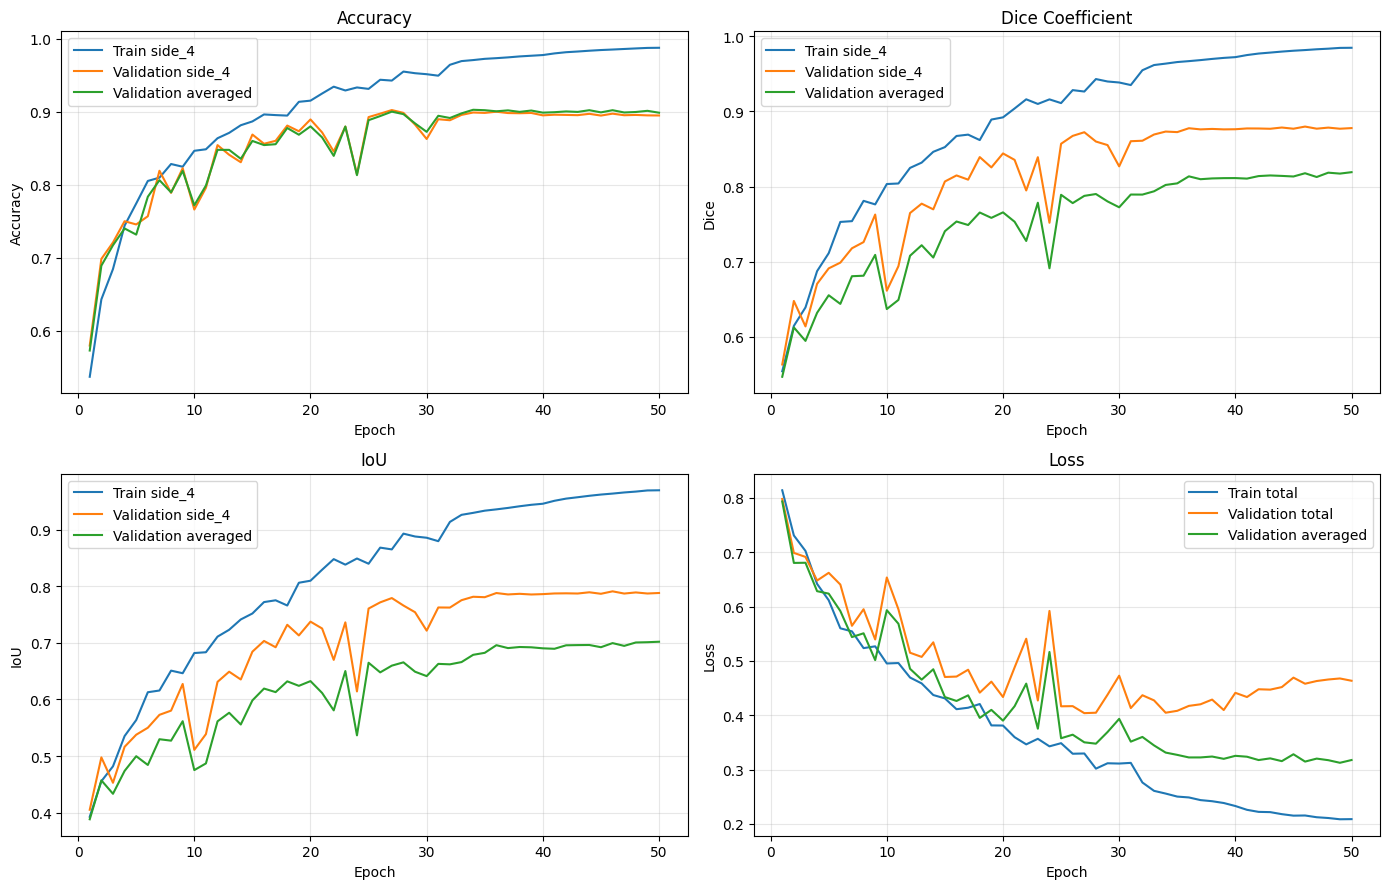


Test image 1/16: testB_1.png
  IoU                 : 0.6951
  Recall              : 0.8539
  Precision           : 0.7889
  Dice Coefficient    : 0.8201
  Boundary F1         : 0.3318
  Boundary Recall     : 0.7028
  Boundary Precision  : 0.2171

Test image 2/16: testB_10.png
  IoU                 : 0.7033
  Recall              : 0.8775
  Precision           : 0.7798
  Dice Coefficient    : 0.8258
  Boundary F1         : 0.4134
  Boundary Recall     : 0.5844
  Boundary Precision  : 0.3198

Test image 3/16: testB_11.png
  IoU                 : 0.9488
  Recall              : 0.9786
  Precision           : 0.9689
  Dice Coefficient    : 0.9737
  Boundary F1         : 0.8092
  Boundary Recall     : 0.8532
  Boundary Precision  : 0.7694

Test image 4/16: testB_12.png
  IoU                 : 0.7262
  Recall              : 0.9177
  Precision           : 0.7767
  Dice Coefficient    : 0.8414
  Boundary F1         : 0.3348
  Boundary Recall     : 0.4324
  Boundary Precision  : 0.2732

Test ima

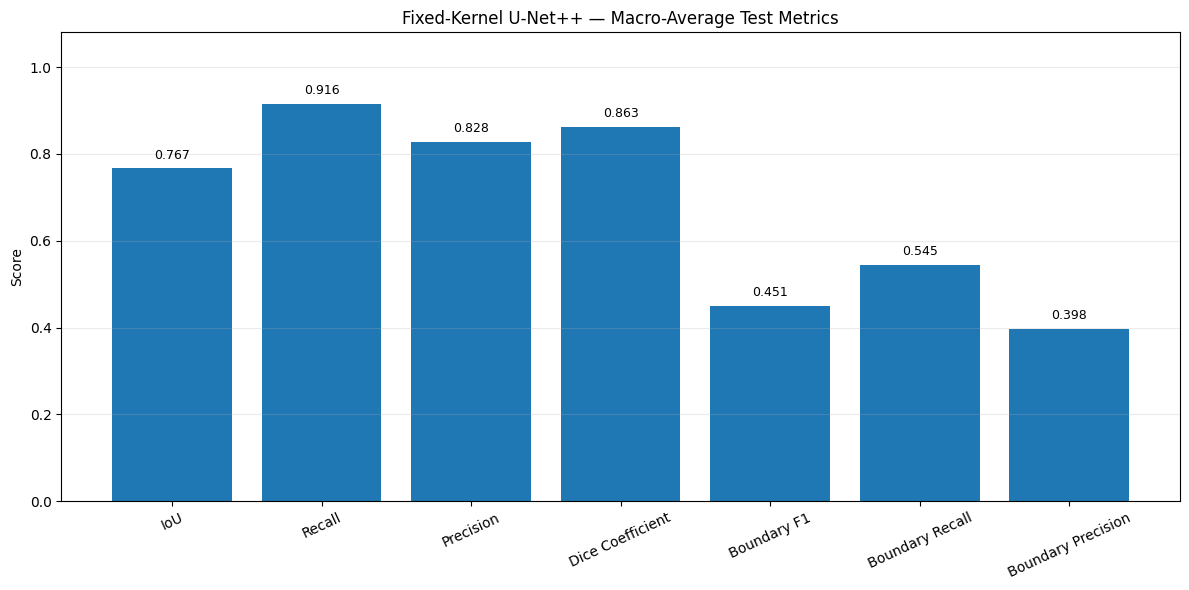

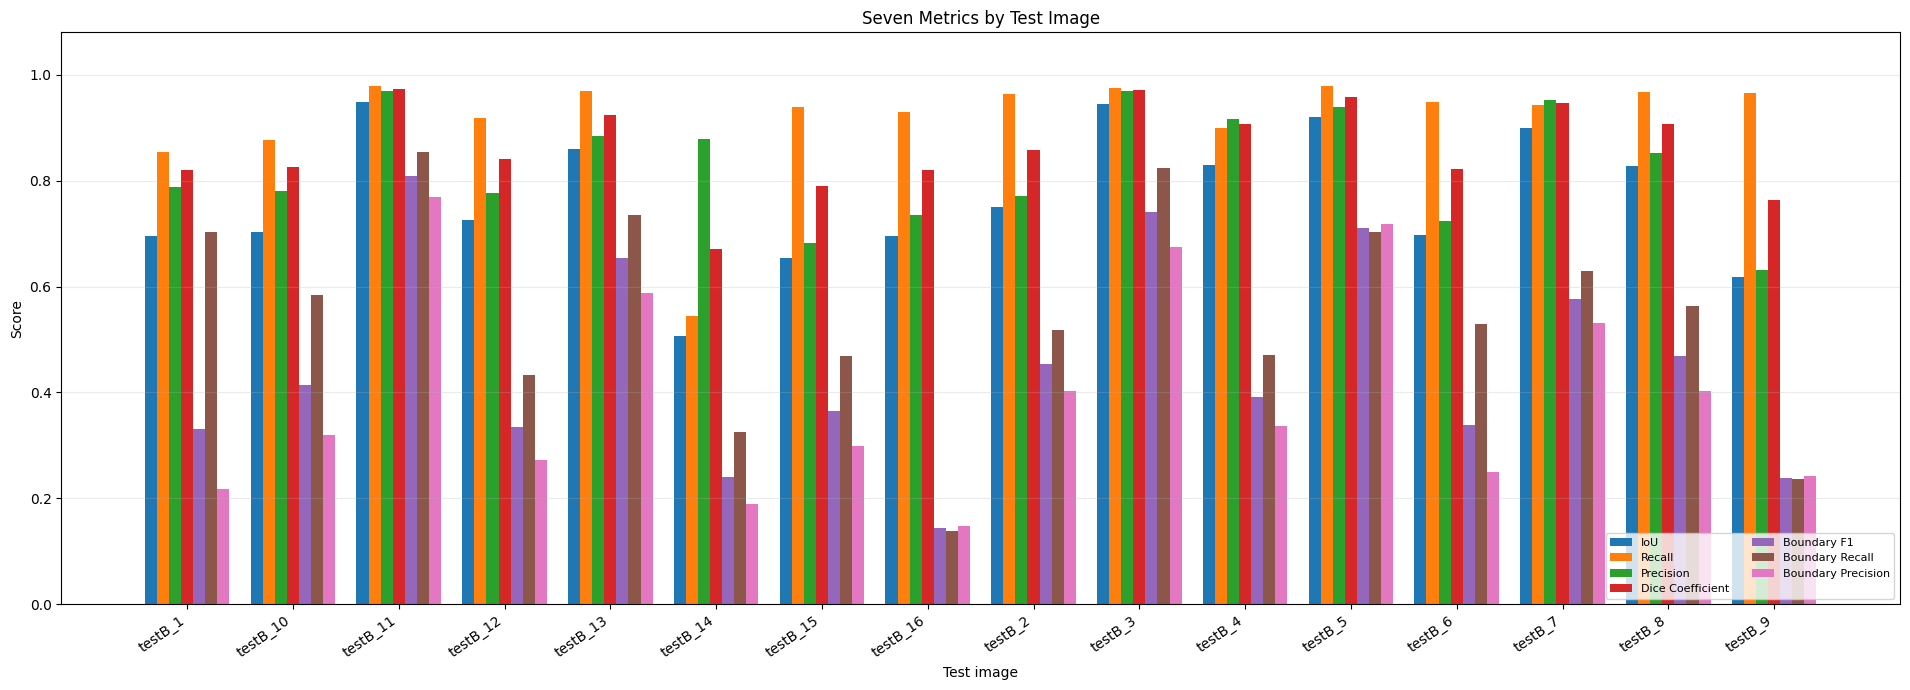

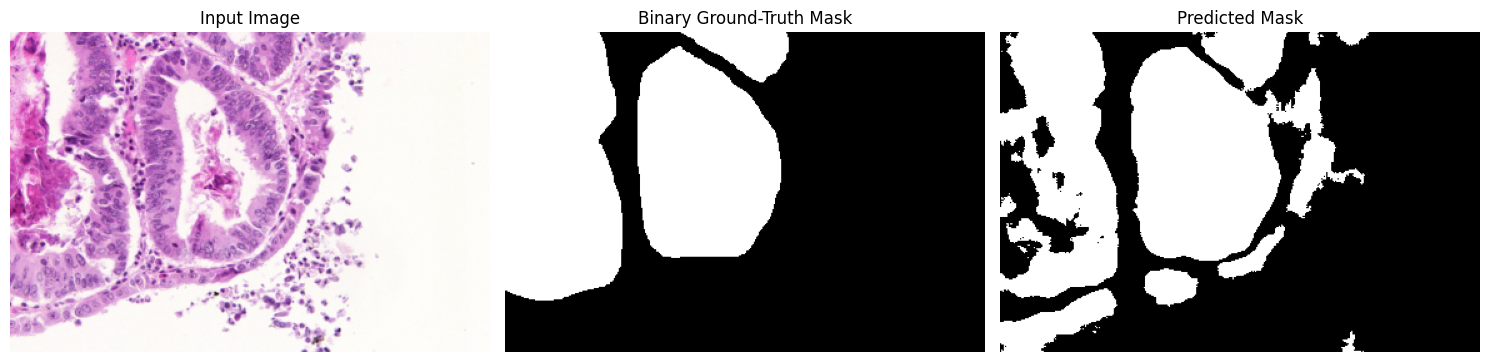

In [5]:
# =========================
# CALLBACK: EVALUATE THE AVERAGED INFERENCE OUTPUT
# =========================
def metric_from_results(results, metric_name):
    """Handle Keras versions that prefix metrics with the output name."""
    if metric_name in results:
        return float(results[metric_name])
    for key, value in results.items():
        if key.endswith("_" + metric_name):
            return float(value)
    raise KeyError(f"Metric {metric_name!r} not found in evaluation results: {list(results)}")


class EvaluateAveragedModel(tf.keras.callbacks.Callback):
    def __init__(self, averaged_model, val_ds):
        super().__init__()
        self.averaged_model = averaged_model
        self.val_ds = val_ds

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        results = self.averaged_model.evaluate(self.val_ds, verbose=0, return_dict=True)
        logs["val_avg_loss"] = float(results["loss"])
        logs["val_avg_accuracy"] = metric_from_results(results, "accuracy")
        logs["val_avg_dice_coef"] = metric_from_results(results, "dice_coef")
        logs["val_avg_iou_coef"] = metric_from_results(results, "iou_coef")
        print(
            f"\nval_avg_loss={logs['val_avg_loss']:.4f}  "
            f"val_avg_dice_coef={logs['val_avg_dice_coef']:.4f}  "
            f"val_avg_iou_coef={logs['val_avg_iou_coef']:.4f}"
        )

paper_eval_cb = EvaluateAveragedModel(infer_model, val_ds_single)

callbacks = [
    paper_eval_cb,
    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(OUTPUT_DIR, "best_unetpp_fixedkernel_train.keras"),
        monitor="val_avg_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_avg_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_avg_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1,
        min_lr=1e-7
    )
]

# =========================
# TRAIN
# =========================
history = train_model.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# Save the averaged inference model after EarlyStopping has restored its best weights.
final_model_path = os.path.join(OUTPUT_DIR, "unetpp_fixedkernel_inference.keras")
infer_model.save(final_model_path)
print("Saved inference model:", final_model_path)

# =========================
# TRAINING CURVES
# =========================
def plot_training_curves(history):
    hist = history.history
    epochs_range = range(1, len(hist.get("loss", [])) + 1)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))

    def plot_if_present(ax, keys, labels, title, ylabel):
        plotted = False
        for key, label in zip(keys, labels):
            if key in hist:
                ax.plot(epochs_range, hist[key], label=label)
                plotted = True
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
        if plotted:
            ax.legend()

    plot_if_present(axes[0, 0], ["side_4_accuracy", "val_side_4_accuracy", "val_avg_accuracy"],
                    ["Train side_4", "Validation side_4", "Validation averaged"], "Accuracy", "Accuracy")
    plot_if_present(axes[0, 1], ["side_4_dice_coef", "val_side_4_dice_coef", "val_avg_dice_coef"],
                    ["Train side_4", "Validation side_4", "Validation averaged"], "Dice Coefficient", "Dice")
    plot_if_present(axes[1, 0], ["side_4_iou_coef", "val_side_4_iou_coef", "val_avg_iou_coef"],
                    ["Train side_4", "Validation side_4", "Validation averaged"], "IoU", "IoU")
    plot_if_present(axes[1, 1], ["loss", "val_loss", "val_avg_loss"],
                    ["Train total", "Validation total", "Validation averaged"], "Loss", "Loss")

    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=160, bbox_inches="tight")
    plt.show()

plot_training_curves(history)

# =========================
# SEVEN PER-IMAGE METRICS
# =========================
METRIC_COLUMNS = [
    "IoU", "Recall", "Precision", "Dice Coefficient",
    "Boundary F1", "Boundary Recall", "Boundary Precision"
]


def safe_ratio(numerator, denominator, empty_value=0.0):
    return float(numerator / denominator) if denominator else float(empty_value)


def binary_metrics(y_true, y_pred):
    """Pixel metrics computed from binary masks."""
    gt = np.asarray(y_true).squeeze().astype(bool)
    pred = np.asarray(y_pred).squeeze().astype(bool)

    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    union = tp + fp + fn
    dice_denominator = 2 * tp + fp + fn

    iou = safe_ratio(tp, union, empty_value=1.0)
    precision = safe_ratio(tp, tp + fp, empty_value=(1.0 if (tp + fn) == 0 else 0.0))
    recall = safe_ratio(tp, tp + fn, empty_value=(1.0 if (tp + fp) == 0 else 0.0))
    dice = safe_ratio(2 * tp, dice_denominator, empty_value=1.0)

    # Derive boundaries from the foreground masks using erosion; no boundary GT files are used.
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    gt_boundary = gt_u8 - cv2.erode(gt_u8, erode_kernel, iterations=1)
    pred_boundary = pred_u8 - cv2.erode(pred_u8, erode_kernel, iterations=1)

    tol = int(BOUNDARY_TOLERANCE_PX)
    tolerance_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    gt_boundary_dilated = cv2.dilate(gt_boundary, tolerance_kernel, iterations=1)
    pred_boundary_dilated = cv2.dilate(pred_boundary, tolerance_kernel, iterations=1)

    matched_pred_boundary = int(np.logical_and(pred_boundary > 0, gt_boundary_dilated > 0).sum())
    matched_gt_boundary = int(np.logical_and(gt_boundary > 0, pred_boundary_dilated > 0).sum())
    pred_boundary_count = int((pred_boundary > 0).sum())
    gt_boundary_count = int((gt_boundary > 0).sum())

    boundary_precision = safe_ratio(
        matched_pred_boundary, pred_boundary_count,
        empty_value=(1.0 if gt_boundary_count == 0 else 0.0)
    )
    boundary_recall = safe_ratio(
        matched_gt_boundary, gt_boundary_count,
        empty_value=(1.0 if pred_boundary_count == 0 else 0.0)
    )
    if pred_boundary_count == 0 and gt_boundary_count == 0:
        boundary_f1 = 1.0
    elif boundary_precision + boundary_recall == 0:
        boundary_f1 = 0.0
    else:
        boundary_f1 = (2.0 * boundary_precision * boundary_recall) / (boundary_precision + boundary_recall)

    return {
        "IoU": iou,
        "Recall": recall,
        "Precision": precision,
        "Dice Coefficient": dice,
        "Boundary F1": boundary_f1,
        "Boundary Recall": boundary_recall,
        "Boundary Precision": boundary_precision,
    }


# Evaluate each held-out image separately. The macro average below gives each image equal weight.
per_image_rows = []
for index, (img_path, mask_path) in enumerate(test_pairs, start=1):
    image, gt_mask = load_image_mask(img_path, mask_path)
    pred_prob = infer_model.predict(np.expand_dims(image, axis=0), verbose=0)[0]
    pred_mask = (pred_prob[..., 0] >= 0.5).astype(np.uint8)
    gt_binary = (gt_mask[..., 0] >= 0.5).astype(np.uint8)

    metrics = binary_metrics(gt_binary, pred_mask)
    row = {"Image": os.path.basename(img_path), **metrics}
    per_image_rows.append(row)

    pred_output_path = os.path.join(
        OUTPUT_DIR, "predicted_masks", f"{Path(img_path).stem}_pred.png"
    )
    cv2.imwrite(pred_output_path, pred_mask * 255)

    print(f"\nTest image {index}/{len(test_pairs)}: {os.path.basename(img_path)}")
    for metric_name in METRIC_COLUMNS:
        print(f"  {metric_name:20s}: {metrics[metric_name]:.4f}")

per_image_df = pd.DataFrame(per_image_rows, columns=["Image"] + METRIC_COLUMNS)
summary_values = per_image_df[METRIC_COLUMNS].mean()
summary_df = pd.DataFrame([summary_values.to_dict()])
summary_df.insert(0, "Aggregation", "Macro average over test images")

per_image_csv = os.path.join(OUTPUT_DIR, "per_image_metrics.csv")
summary_csv = os.path.join(OUTPUT_DIR, "summary_metrics.csv")
per_image_df.to_csv(per_image_csv, index=False)
summary_df.to_csv(summary_csv, index=False)

print("\n================ MACRO-AVERAGE VALIDATION METRICS ================")
for metric_name in METRIC_COLUMNS:
    print(f"{metric_name:20s}: {summary_values[metric_name]:.4f}")
print("\nSaved per-image CSV:", per_image_csv)
print("Saved summary CSV:", summary_csv)
print("Predicted masks directory:", os.path.join(OUTPUT_DIR, "predicted_masks"))

# =========================
# OVERALL MACRO-AVERAGE BAR GRAPH (WITH VALUE LABELS)
# =========================
fig, ax = plt.subplots(figsize=(12, 6))
bar_values = [float(summary_values[name]) for name in METRIC_COLUMNS]
bars = ax.bar(METRIC_COLUMNS, bar_values)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.set_title("Fixed-Kernel U-Net++ — Macro-Average Test Metrics")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
for bar, value in zip(bars, bar_values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015,
            f"{value:.3f}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "overall_macro_metrics.png"), dpi=160, bbox_inches="tight")
plt.show()

# =========================
# PER-IMAGE METRIC GRAPH
# =========================
fig, ax = plt.subplots(figsize=(max(12, len(per_image_df) * 1.2), 7))
x = np.arange(len(per_image_df))
bar_width = 0.8 / len(METRIC_COLUMNS)
for metric_index, metric_name in enumerate(METRIC_COLUMNS):
    offsets = x - 0.4 + (metric_index + 0.5) * bar_width
    ax.bar(offsets, per_image_df[metric_name].values, width=bar_width, label=metric_name)
ax.set_ylim(0, 1.08)
ax.set_xlabel("Test image")
ax.set_ylabel("Score")
ax.set_title("Seven Metrics by Test Image")
ax.set_xticks(x)
ax.set_xticklabels([Path(name).stem for name in per_image_df["Image"]], rotation=35, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(ncol=2, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "test_per_image_metrics.png"), dpi=160, bbox_inches="tight")
plt.show()

# =========================
# EXAMPLE INPUT / GROUND TRUTH / PREDICTION
# =========================
def show_prediction(model, pair):
    img_path, mask_path = pair
    image, mask = load_image_mask(img_path, mask_path)
    pred = model.predict(np.expand_dims(image, axis=0), verbose=0)[0, ..., 0]
    pred_mask = (pred >= 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(image)
    plt.title("Input Image")
    plt.axis("off")
    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("Binary Ground-Truth Mask")
    plt.axis("off")
    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask, cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

if test_pairs:
    show_prediction(infer_model, test_pairs[0])


In [6]:
# Save predicted masks for all validation images
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predicted_masks")
os.makedirs(PREDICTION_DIR, exist_ok=True)

PRED_THRESHOLD = globals().get("PRED_THRESHOLD", 0.5)

for idx, (image_path, mask_path) in enumerate(val_pairs, start=1):

    # Load image using the notebook's existing preprocessing
    image, _ = load_image_mask(
        str(image_path).encode(),
        str(mask_path).encode()
    )

    # U-Net++ averaged inference prediction (sigmoid already applied)
    pred_prob = infer_model.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )[0].squeeze()

    # Convert to binary mask: background=0, foreground=255
    pred_mask = (
        (pred_prob >= PRED_THRESHOLD).astype(np.uint8) * 255
    )

    # Save predicted mask as PNG
    filename = (
        f"{os.path.splitext(os.path.basename(str(image_path)))[0]}"
        "_prediction.png"
    )
    save_path = os.path.join(PREDICTION_DIR, filename)

    if not cv2.imwrite(save_path, pred_mask):
        raise IOError(f"Failed to save: {save_path}")

    print(f"[{idx}/{len(val_pairs)}] Saved: {filename}")

print(f"\nAll predicted masks saved in:\n{PREDICTION_DIR}")

[1/16] Saved: testA_1_prediction.png
[2/16] Saved: testA_10_prediction.png
[3/16] Saved: testA_11_prediction.png
[4/16] Saved: testA_12_prediction.png
[5/16] Saved: testA_13_prediction.png
[6/16] Saved: testA_14_prediction.png
[7/16] Saved: testA_15_prediction.png
[8/16] Saved: testA_16_prediction.png
[9/16] Saved: testA_2_prediction.png
[10/16] Saved: testA_3_prediction.png
[11/16] Saved: testA_4_prediction.png
[12/16] Saved: testA_5_prediction.png
[13/16] Saved: testA_6_prediction.png
[14/16] Saved: testA_7_prediction.png
[15/16] Saved: testA_8_prediction.png
[16/16] Saved: testA_9_prediction.png

All predicted masks saved in:
/raid/home/dgx1725/unetpp_mod2_fixedkernel_warwick_outputs/predicted_masks
